# PHP_pre: raw vs. order=8 vs. order=4 notch filter, frequency by frequency

Compares three things at each frequency bin: the raw (unfiltered) PSD, the
8th-order Butterworth notch (the default in `psd_compute_notch.py`), and the
4th-order variant -- for halfwidths 2, 3, and 4 Hz. Done twice: once on the
uninterpolated PSDs, and once after filling 56-64 Hz with `specparam`'s
`interpolate_spectrum` (buffer=3) on all three (raw included, so the
comparison in that band isn't dominated by the notch's own designed dip).

All PSDs were already computed by `psd_raw_vs_notch_php_pre.ipynb` (order=8)
and `psd_raw_vs_notch_php_pre_order4.ipynb` (order=4) and live in
`notch_trials/` -- this notebook only loads and compares, no recomputation.

Run in the `ebb-dev` environment.

In [1]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ebb.core.naming import parse_animal_id

## Paths

In [2]:
OUT_DIR = Path("/Users/leahmcintyre/Data/nri/PHP.eB/PHP_pre/notch_trials")
RAW_PKL = OUT_DIR / "psds_php_pre_raw.pkl"

NOTCH_HALFWIDTHS = [2, 3, 4]  # Hz; stopband is 60 +/- halfwidth
ORDER8_PKLS = {hw: OUT_DIR / f"psds_php_pre_notch_h{hw}.pkl" for hw in NOTCH_HALFWIDTHS}
ORDER4_PKLS = {hw: OUT_DIR / f"psds_php_pre_notch_h{hw}_order4.pkl" for hw in NOTCH_HALFWIDTHS}

for hw in NOTCH_HALFWIDTHS:
    assert ORDER8_PKLS[hw].exists(), f"missing {ORDER8_PKLS[hw]}"
    assert ORDER4_PKLS[hw].exists(), f"missing {ORDER4_PKLS[hw]}"
print("All order8/order4 pkls present for halfwidths", NOTCH_HALFWIDTHS)

All order8/order4 pkls present for halfwidths [2, 3, 4]


## Load from disk

No recomputation -- everything here was already produced by the two reference notebooks.

In [3]:
def _simplify_behavior(records):
    """Collapse each record's ('threshold', state) behavior tuple down to just state."""
    for rec in records:
        rec["behavior"] = rec["behavior"][1]
    return records


def _load(path):
    with open(path, "rb") as f:
        return _simplify_behavior(pickle.load(f))


raw_records = _load(RAW_PKL)
order8_records_by_hw = {hw: _load(p) for hw, p in ORDER8_PKLS.items()}
order4_records_by_hw = {hw: _load(p) for hw, p in ORDER4_PKLS.items()}

print(f"raw: {len(raw_records)} records")
for hw in NOTCH_HALFWIDTHS:
    print(f"order8 h={hw}: {len(order8_records_by_hw[hw])} records")
    print(f"order4 h={hw}: {len(order4_records_by_hw[hw])} records")

raw: 114 records
order8 h=2: 114 records
order4 h=2: 114 records
order8 h=3: 114 records
order4 h=3: 114 records
order8 h=4: 114 records
order4 h=4: 114 records


## Sanity checks: matched animals/behaviors, identical frequency axis

In [4]:
def record_key(rec):
    return (parse_animal_id(Path(rec["path"])), rec["behavior"])


raw_by_key = {record_key(r): r for r in raw_records}
order8_by_key_by_hw = {hw: {record_key(r): r for r in recs} for hw, recs in order8_records_by_hw.items()}
order4_by_key_by_hw = {hw: {record_key(r): r for r in recs} for hw, recs in order4_records_by_hw.items()}

common_keys = sorted(
    set(raw_by_key)
    .intersection(*(set(d) for d in order8_by_key_by_hw.values()))
    .intersection(*(set(d) for d in order4_by_key_by_hw.values()))
)
print(f"{len(common_keys)} (animal, behavior) pairs common to raw + order8 + order4, all halfwidths")

for hw in NOTCH_HALFWIDTHS:
    freqs_match = all(
        np.array_equal(raw_by_key[k]["freqs"], order8_by_key_by_hw[hw][k]["freqs"])
        and np.array_equal(raw_by_key[k]["freqs"], order4_by_key_by_hw[hw][k]["freqs"])
        for k in common_keys
    )
    print(f"h={hw}: freq axes identical across raw/order8/order4 = {freqs_match}")

114 (animal, behavior) pairs common to raw + order8 + order4, all halfwidths
h=2: freq axes identical across raw/order8/order4 = True
h=3: freq axes identical across raw/order8/order4 = True
h=4: freq axes identical across raw/order8/order4 = True


## Uninterpolated: tidy long-format comparison table

One row per (halfwidth, animal, behavior, channel, freq), with `psd_raw`,
`psd_order8`, `psd_order4` side by side. `delta_db_o8`/`delta_db_o4` are each
order's notch effect relative to raw; `delta_db_o8_vs_o4` is the direct
order-to-order comparison.

In [5]:
hw_colors = {2: "steelblue", 3: "goldenrod", 4: "tomato"}

rows = []
for hw in NOTCH_HALFWIDTHS:
    order8_by_key = order8_by_key_by_hw[hw]
    order4_by_key = order4_by_key_by_hw[hw]
    for _animal, _behavior in common_keys:
        _r_raw = raw_by_key[(_animal, _behavior)]
        _r_o8 = order8_by_key[(_animal, _behavior)]
        _r_o4 = order4_by_key[(_animal, _behavior)]
        _freqs = np.asarray(_r_raw["freqs"])
        psd_raw = np.asarray(_r_raw["psd"])
        psd_o8 = np.asarray(_r_o8["psd"])
        psd_o4 = np.asarray(_r_o4["psd"])
        for ci, ch in enumerate(_r_raw["channels"]):
            rows.append(
                pd.DataFrame(
                    {
                        "halfwidth": hw,
                        "animal": _animal,
                        "behavior": _behavior,
                        "channel": ch,
                        "freq": _freqs,
                        "psd_raw": psd_raw[ci],
                        "psd_order8": psd_o8[ci],
                        "psd_order4": psd_o4[ci],
                    }
                )
            )

df = pd.concat(rows, ignore_index=True)
df["delta_db_o8"] = 10 * np.log10(df["psd_order8"]) - 10 * np.log10(df["psd_raw"])
df["delta_db_o4"] = 10 * np.log10(df["psd_order4"]) - 10 * np.log10(df["psd_raw"])
df["delta_db_o8_vs_o4"] = 10 * np.log10(df["psd_order8"]) - 10 * np.log10(df["psd_order4"])
df.head()

,halfwidth,animal,behavior,channel,freq,psd_raw,psd_order8,psd_order4,delta_db_o8,delta_db_o4,delta_db_o8_vs_o4
0,2,CW0DA1,nrem,0,0.0,8.730157,8.548415,8.548377,-0.091365,-0.091384,1.936588e-05
1,2,CW0DA1,nrem,0,0.5,32.696114,32.683731,32.683769,-0.001645,-0.001640,-4.961946e-06
2,2,CW0DA1,nrem,0,1.0,81.456056,81.013395,81.013494,-0.023665,-0.023660,-5.342771e-06
3,2,CW0DA1,nrem,0,1.5,149.462854,149.142312,149.142331,-0.009324,-0.009323,-5.579708e-07
4,2,CW0DA1,nrem,0,2.0,221.127846,221.390342,221.390353,0.005152,0.005153,-2.087604e-07


## Plot: mean effect vs. frequency, order8 vs. order4 (each relative to raw)

Solid = order8, dashed = order4, colored by halfwidth.

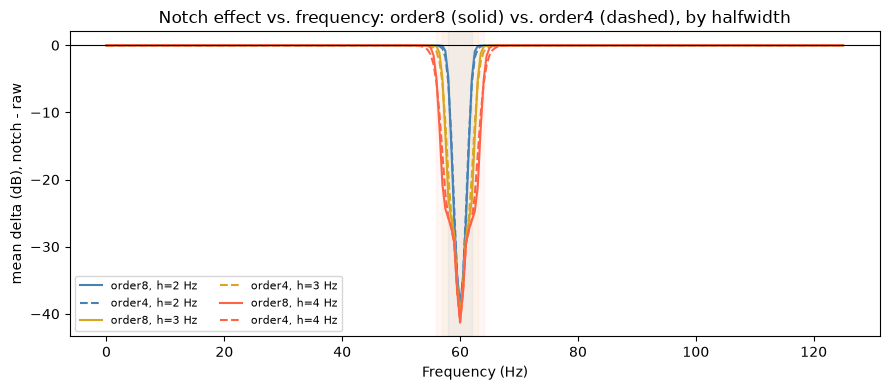

In [6]:
mean_o8_by_hw = {hw: sub.groupby("freq")["delta_db_o8"].mean() for hw, sub in df.groupby("halfwidth")}
mean_o4_by_hw = {hw: sub.groupby("freq")["delta_db_o4"].mean() for hw, sub in df.groupby("halfwidth")}

fig, ax = plt.subplots(figsize=(9, 4))
for hw in NOTCH_HALFWIDTHS:
    color = hw_colors.get(hw)
    ax.plot(mean_o8_by_hw[hw].index, mean_o8_by_hw[hw].values, label=f"order8, h={hw} Hz", color=color)
    ax.plot(
        mean_o4_by_hw[hw].index, mean_o4_by_hw[hw].values, label=f"order4, h={hw} Hz", color=color, ls="--"
    )
    ax.axvspan(60 - hw, 60 + hw, color=color, alpha=0.05)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("mean delta (dB), notch - raw")
ax.set_title("Notch effect vs. frequency: order8 (solid) vs. order4 (dashed), by halfwidth")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()

## Plot: mean effect vs. frequency, order8 vs. order4 directly

This is the comparison that matters most for "does filter order change
anything": order8's PSD vs. order4's PSD, with raw out of the picture
entirely.

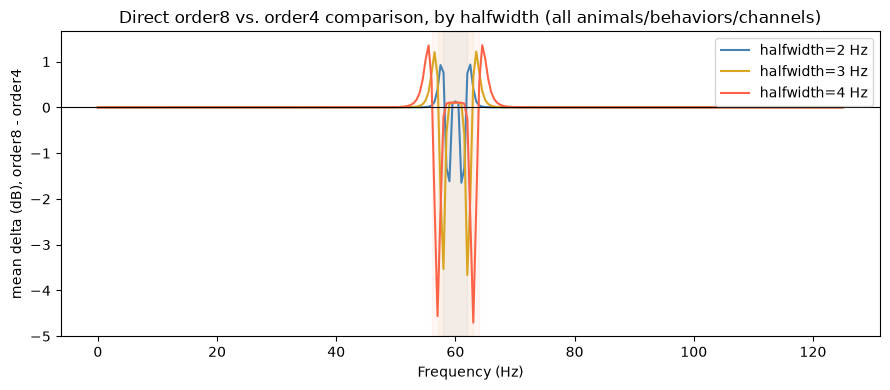

In [7]:
mean_o8_vs_o4_by_hw = {
    hw: sub.groupby("freq")["delta_db_o8_vs_o4"].mean() for hw, sub in df.groupby("halfwidth")
}

fig, ax = plt.subplots(figsize=(9, 4))
for hw in NOTCH_HALFWIDTHS:
    ax.plot(
        mean_o8_vs_o4_by_hw[hw].index,
        mean_o8_vs_o4_by_hw[hw].values,
        label=f"halfwidth={hw} Hz",
        color=hw_colors.get(hw),
    )
    ax.axvspan(60 - hw, 60 + hw, color=hw_colors.get(hw), alpha=0.05)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("mean delta (dB), order8 - order4")
ax.set_title("Direct order8 vs. order4 comparison, by halfwidth (all animals/behaviors/channels)")
ax.legend()
fig.tight_layout()

## Percent-difference comparison (uninterpolated)

Same comparisons as above, expressed as `(a / b - 1) * 100` instead of dB.

In [8]:
df["pct_o8"] = (df["psd_order8"] / df["psd_raw"] - 1) * 100
df["pct_o4"] = (df["psd_order4"] / df["psd_raw"] - 1) * 100
df["pct_o8_vs_o4"] = (df["psd_order8"] / df["psd_order4"] - 1) * 100
df[["halfwidth", "animal", "behavior", "channel", "freq", "delta_db_o8", "pct_o8"]].head()

,halfwidth,animal,behavior,channel,freq,delta_db_o8,pct_o8
0,2,CW0DA1,nrem,0,0.0,-0.091365,-2.081777
1,2,CW0DA1,nrem,0,0.5,-0.001645,-0.037874
2,2,CW0DA1,nrem,0,1.0,-0.023665,-0.543436
3,2,CW0DA1,nrem,0,1.5,-0.009324,-0.214463
4,2,CW0DA1,nrem,0,2.0,0.005152,0.118708


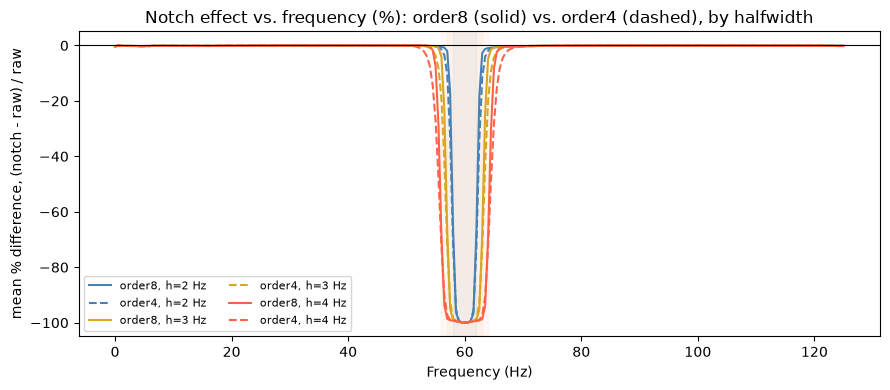

In [9]:
mean_pct_o8_by_hw = {hw: sub.groupby("freq")["pct_o8"].mean() for hw, sub in df.groupby("halfwidth")}
mean_pct_o4_by_hw = {hw: sub.groupby("freq")["pct_o4"].mean() for hw, sub in df.groupby("halfwidth")}

fig, ax = plt.subplots(figsize=(9, 4))
for hw in NOTCH_HALFWIDTHS:
    color = hw_colors.get(hw)
    ax.plot(
        mean_pct_o8_by_hw[hw].index, mean_pct_o8_by_hw[hw].values, label=f"order8, h={hw} Hz", color=color
    )
    ax.plot(
        mean_pct_o4_by_hw[hw].index, mean_pct_o4_by_hw[hw].values, label=f"order4, h={hw} Hz", color=color, ls="--"
    )
    ax.axvspan(60 - hw, 60 + hw, color=color, alpha=0.05)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("mean % difference, (notch - raw) / raw")
ax.set_title("Notch effect vs. frequency (%): order8 (solid) vs. order4 (dashed), by halfwidth")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()

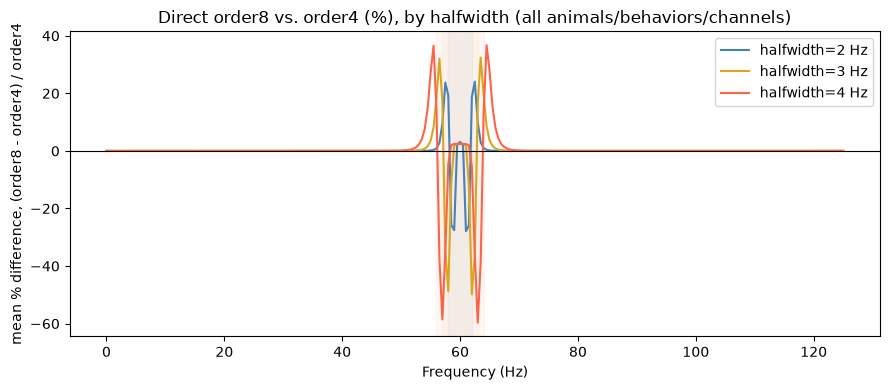

In [10]:
mean_pct_o8_vs_o4_by_hw = {
    hw: sub.groupby("freq")["pct_o8_vs_o4"].mean() for hw, sub in df.groupby("halfwidth")
}

fig, ax = plt.subplots(figsize=(9, 4))
for hw in NOTCH_HALFWIDTHS:
    ax.plot(
        mean_pct_o8_vs_o4_by_hw[hw].index,
        mean_pct_o8_vs_o4_by_hw[hw].values,
        label=f"halfwidth={hw} Hz",
        color=hw_colors.get(hw),
    )
    ax.axvspan(60 - hw, 60 + hw, color=hw_colors.get(hw), alpha=0.05)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("mean % difference, (order8 - order4) / order4")
ax.set_title("Direct order8 vs. order4 (%), by halfwidth (all animals/behaviors/channels)")
ax.legend()
fig.tight_layout()

## Single-animal overlay: raw vs. order8 vs. order4 (uninterpolated)

Edit `ANIMAL`/`BEHAVIOR` to look at a different animal.

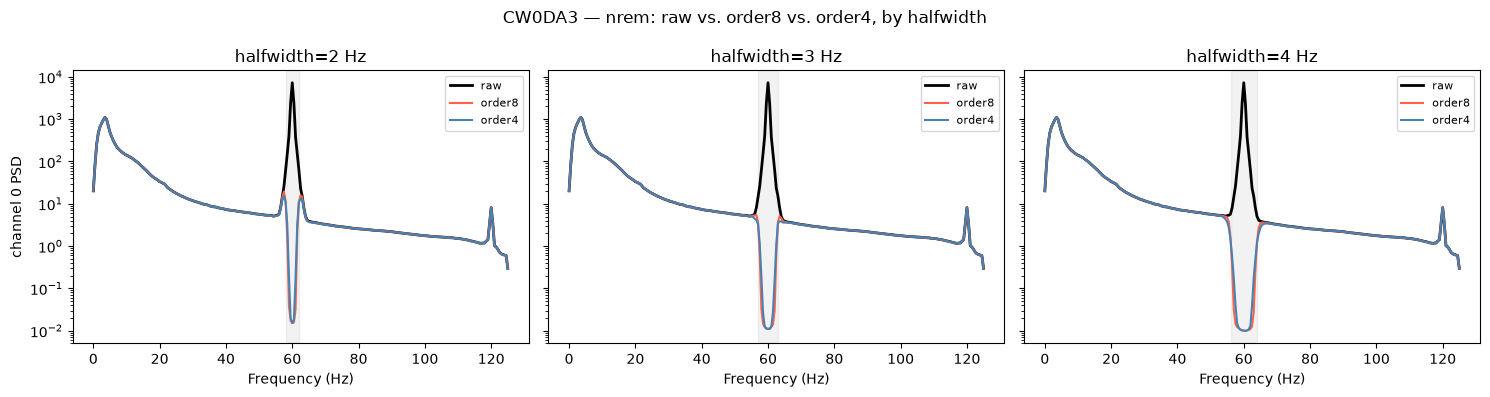

In [11]:
ANIMAL = "CW0DA3"
BEHAVIOR = "nrem"  # "wake" / "nrem" / "rem"

available_animals = sorted({a for a, b in common_keys})
if (ANIMAL, BEHAVIOR) not in common_keys:
    raise ValueError(
        f"{(ANIMAL, BEHAVIOR)!r} not in common_keys.\n"
        f"Available animals: {available_animals}\n"
        f"Available behaviors: {sorted({b for a, b in common_keys})}"
    )
animal, behavior = ANIMAL, BEHAVIOR
r_raw = raw_by_key[(animal, behavior)]
freqs = np.asarray(r_raw["freqs"])
channels = r_raw["channels"]

fig, axes = plt.subplots(1, len(NOTCH_HALFWIDTHS), figsize=(5 * len(NOTCH_HALFWIDTHS), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, hw in zip(axes, NOTCH_HALFWIDTHS):
    r_o8 = order8_by_key_by_hw[hw][(animal, behavior)]
    r_o4 = order4_by_key_by_hw[hw][(animal, behavior)]
    ax.semilogy(freqs, r_raw["psd"][0], label="raw", color="black", lw=2)
    ax.semilogy(freqs, r_o8["psd"][0], label="order8", color="tomato")
    ax.semilogy(freqs, r_o4["psd"][0], label="order4", color="steelblue")
    ax.axvspan(60 - hw, 60 + hw, color="gray", alpha=0.1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_title(f"halfwidth={hw} Hz")
    ax.legend(fontsize=8)
axes[0].set_ylabel(f"channel {channels[0]} PSD")
fig.suptitle(f"{animal} — {behavior}: raw vs. order8 vs. order4, by halfwidth")
fig.tight_layout()

## Interpolated comparison: fill 56-64 Hz before comparing

Same three-way comparison, but 56-64 Hz is filled in first on raw, order8,
and order4 alike, via `specparam`'s `interpolate_spectrum` (log-log space,
median-anchored) with `buffer=3` -- note this buffer is much smaller than
the buffer=10 used elsewhere in the reference notebooks, so anchors are
closer to the window edge and more sensitive to a single noisy bin there.

In [12]:
from specparam.utils.spectral import interpolate_spectrum

INTERP_RANGE = [56, 64]
INTERP_BUFFER = 3


def interpolate_record(rec, interp_range=INTERP_RANGE, buffer=INTERP_BUFFER):
    """Return a copy of a PSDResult dict with every channel's psd interpolated
    across interp_range Hz via specparam's log-log, median-anchored recipe."""
    freqs = np.asarray(rec["freqs"])
    psd = np.asarray(rec["psd"])
    interp_psd = np.stack(
        [interpolate_spectrum(freqs, psd[ci], interp_range, buffer=buffer)[1] for ci in range(psd.shape[0])]
    )
    out = dict(rec)
    out["psd"] = interp_psd
    return out


raw_by_key_interp = {k: interpolate_record(r) for k, r in raw_by_key.items()}
order8_by_key_by_hw_interp = {
    hw: {k: interpolate_record(r) for k, r in order8_by_key.items()}
    for hw, order8_by_key in order8_by_key_by_hw.items()
}
order4_by_key_by_hw_interp = {
    hw: {k: interpolate_record(r) for k, r in order4_by_key.items()}
    for hw, order4_by_key in order4_by_key_by_hw.items()
}
print(f"Interpolated raw + order8 + order4 (all halfwidths) across {INTERP_RANGE} Hz, buffer={INTERP_BUFFER}")

Interpolated raw + order8 + order4 (all halfwidths) across [56, 64] Hz, buffer=3


### Interpolated: tidy long-format comparison table

In [13]:
rows_interp = []
for hw in NOTCH_HALFWIDTHS:
    order8_by_key_i = order8_by_key_by_hw_interp[hw]
    order4_by_key_i = order4_by_key_by_hw_interp[hw]
    for _animal, _behavior in common_keys:
        _r_raw = raw_by_key_interp[(_animal, _behavior)]
        _r_o8 = order8_by_key_i[(_animal, _behavior)]
        _r_o4 = order4_by_key_i[(_animal, _behavior)]
        _freqs = np.asarray(_r_raw["freqs"])
        psd_raw = np.asarray(_r_raw["psd"])
        psd_o8 = np.asarray(_r_o8["psd"])
        psd_o4 = np.asarray(_r_o4["psd"])
        for ci, ch in enumerate(_r_raw["channels"]):
            rows_interp.append(
                pd.DataFrame(
                    {
                        "halfwidth": hw,
                        "animal": _animal,
                        "behavior": _behavior,
                        "channel": ch,
                        "freq": _freqs,
                        "psd_raw": psd_raw[ci],
                        "psd_order8": psd_o8[ci],
                        "psd_order4": psd_o4[ci],
                    }
                )
            )

df_interp = pd.concat(rows_interp, ignore_index=True)
df_interp["delta_db_o8"] = 10 * np.log10(df_interp["psd_order8"]) - 10 * np.log10(df_interp["psd_raw"])
df_interp["delta_db_o4"] = 10 * np.log10(df_interp["psd_order4"]) - 10 * np.log10(df_interp["psd_raw"])
df_interp["delta_db_o8_vs_o4"] = 10 * np.log10(df_interp["psd_order8"]) - 10 * np.log10(df_interp["psd_order4"])
df_interp.head()

,halfwidth,animal,behavior,channel,freq,psd_raw,psd_order8,psd_order4,delta_db_o8,delta_db_o4,delta_db_o8_vs_o4
0,2,CW0DA1,nrem,0,0.0,8.730157,8.548415,8.548377,-0.091365,-0.091384,1.936588e-05
1,2,CW0DA1,nrem,0,0.5,32.696114,32.683731,32.683769,-0.001645,-0.001640,-4.961946e-06
2,2,CW0DA1,nrem,0,1.0,81.456056,81.013395,81.013494,-0.023665,-0.023660,-5.342771e-06
3,2,CW0DA1,nrem,0,1.5,149.462854,149.142312,149.142331,-0.009324,-0.009323,-5.579708e-07
4,2,CW0DA1,nrem,0,2.0,221.127846,221.390342,221.390353,0.005152,0.005153,-2.087604e-07


### Interpolated: mean effect vs. frequency, order8 vs. order4 (each relative to raw)

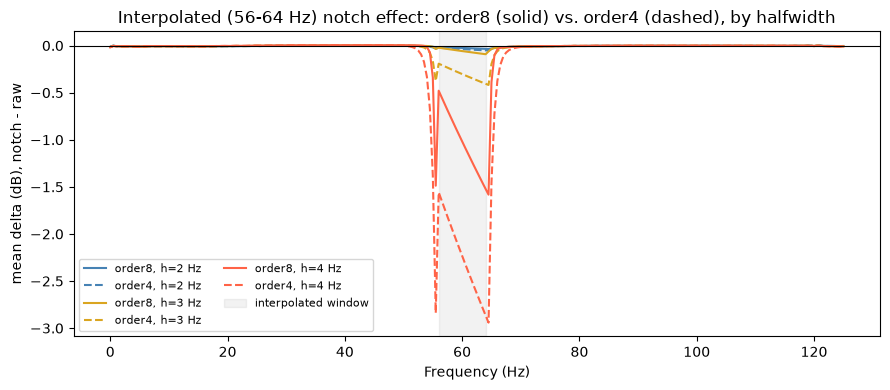

In [14]:
mean_o8_interp_by_hw = {
    hw: sub.groupby("freq")["delta_db_o8"].mean() for hw, sub in df_interp.groupby("halfwidth")
}
mean_o4_interp_by_hw = {
    hw: sub.groupby("freq")["delta_db_o4"].mean() for hw, sub in df_interp.groupby("halfwidth")
}

fig, ax = plt.subplots(figsize=(9, 4))
for hw in NOTCH_HALFWIDTHS:
    color = hw_colors.get(hw)
    ax.plot(
        mean_o8_interp_by_hw[hw].index, mean_o8_interp_by_hw[hw].values, label=f"order8, h={hw} Hz", color=color
    )
    ax.plot(
        mean_o4_interp_by_hw[hw].index,
        mean_o4_interp_by_hw[hw].values,
        label=f"order4, h={hw} Hz",
        color=color,
        ls="--",
    )
ax.axvspan(*INTERP_RANGE, color="gray", alpha=0.1, label="interpolated window")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("mean delta (dB), notch - raw")
ax.set_title(
    f"Interpolated ({INTERP_RANGE[0]}-{INTERP_RANGE[1]} Hz) notch effect: "
    "order8 (solid) vs. order4 (dashed), by halfwidth"
)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()

### Interpolated: mean effect vs. frequency, order8 vs. order4 directly

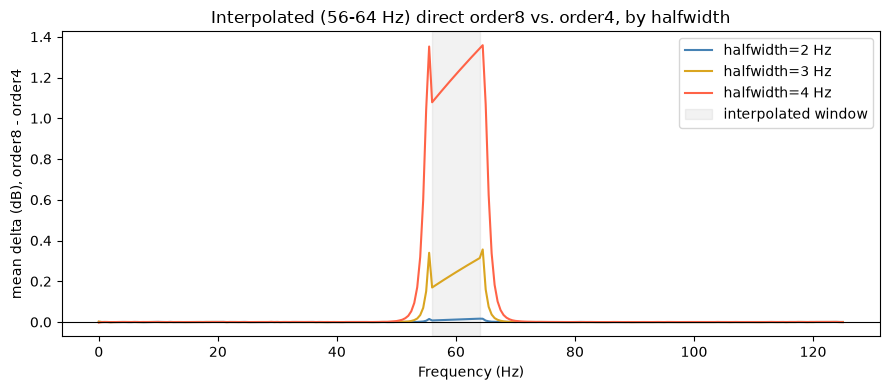

In [15]:
mean_o8_vs_o4_interp_by_hw = {
    hw: sub.groupby("freq")["delta_db_o8_vs_o4"].mean() for hw, sub in df_interp.groupby("halfwidth")
}

fig, ax = plt.subplots(figsize=(9, 4))
for hw in NOTCH_HALFWIDTHS:
    ax.plot(
        mean_o8_vs_o4_interp_by_hw[hw].index,
        mean_o8_vs_o4_interp_by_hw[hw].values,
        label=f"halfwidth={hw} Hz",
        color=hw_colors.get(hw),
    )
ax.axvspan(*INTERP_RANGE, color="gray", alpha=0.1, label="interpolated window")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("mean delta (dB), order8 - order4")
ax.set_title(
    f"Interpolated ({INTERP_RANGE[0]}-{INTERP_RANGE[1]} Hz) direct order8 vs. order4, by halfwidth"
)
ax.legend()
fig.tight_layout()

### Interpolated: percent-difference comparison

In [16]:
df_interp["pct_o8"] = (df_interp["psd_order8"] / df_interp["psd_raw"] - 1) * 100
df_interp["pct_o4"] = (df_interp["psd_order4"] / df_interp["psd_raw"] - 1) * 100
df_interp["pct_o8_vs_o4"] = (df_interp["psd_order8"] / df_interp["psd_order4"] - 1) * 100
df_interp[["halfwidth", "animal", "behavior", "channel", "freq", "delta_db_o8", "pct_o8"]].head()

,halfwidth,animal,behavior,channel,freq,delta_db_o8,pct_o8
0,2,CW0DA1,nrem,0,0.0,-0.091365,-2.081777
1,2,CW0DA1,nrem,0,0.5,-0.001645,-0.037874
2,2,CW0DA1,nrem,0,1.0,-0.023665,-0.543436
3,2,CW0DA1,nrem,0,1.5,-0.009324,-0.214463
4,2,CW0DA1,nrem,0,2.0,0.005152,0.118708


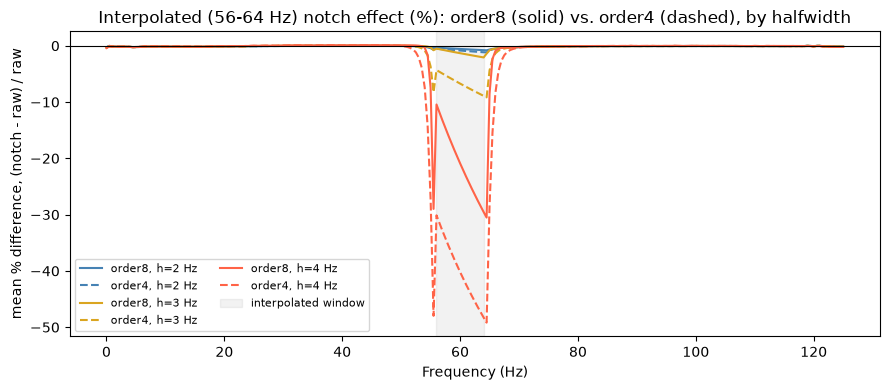

In [17]:
mean_pct_o8_interp_by_hw = {
    hw: sub.groupby("freq")["pct_o8"].mean() for hw, sub in df_interp.groupby("halfwidth")
}
mean_pct_o4_interp_by_hw = {
    hw: sub.groupby("freq")["pct_o4"].mean() for hw, sub in df_interp.groupby("halfwidth")
}

fig, ax = plt.subplots(figsize=(9, 4))
for hw in NOTCH_HALFWIDTHS:
    color = hw_colors.get(hw)
    ax.plot(
        mean_pct_o8_interp_by_hw[hw].index,
        mean_pct_o8_interp_by_hw[hw].values,
        label=f"order8, h={hw} Hz",
        color=color,
    )
    ax.plot(
        mean_pct_o4_interp_by_hw[hw].index,
        mean_pct_o4_interp_by_hw[hw].values,
        label=f"order4, h={hw} Hz",
        color=color,
        ls="--",
    )
ax.axvspan(*INTERP_RANGE, color="gray", alpha=0.1, label="interpolated window")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("mean % difference, (notch - raw) / raw")
ax.set_title(
    f"Interpolated ({INTERP_RANGE[0]}-{INTERP_RANGE[1]} Hz) notch effect (%): "
    "order8 (solid) vs. order4 (dashed), by halfwidth"
)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()

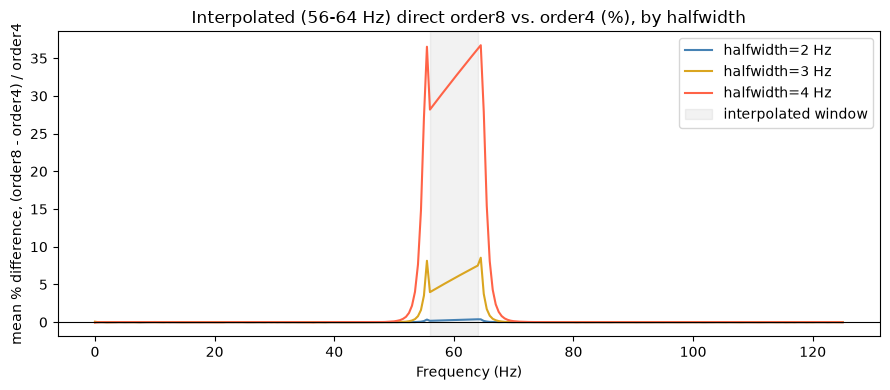

In [18]:
mean_pct_o8_vs_o4_interp_by_hw = {
    hw: sub.groupby("freq")["pct_o8_vs_o4"].mean() for hw, sub in df_interp.groupby("halfwidth")
}

fig, ax = plt.subplots(figsize=(9, 4))
for hw in NOTCH_HALFWIDTHS:
    ax.plot(
        mean_pct_o8_vs_o4_interp_by_hw[hw].index,
        mean_pct_o8_vs_o4_interp_by_hw[hw].values,
        label=f"halfwidth={hw} Hz",
        color=hw_colors.get(hw),
    )
ax.axvspan(*INTERP_RANGE, color="gray", alpha=0.1, label="interpolated window")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("mean % difference, (order8 - order4) / order4")
ax.set_title(f"Interpolated ({INTERP_RANGE[0]}-{INTERP_RANGE[1]} Hz) direct order8 vs. order4 (%), by halfwidth")
ax.legend()
fig.tight_layout()

## Single-animal overlay: raw vs. order8 vs. order4 (interpolated)

Same `ANIMAL`/`BEHAVIOR` pin as above, zoomed to the interpolation window.

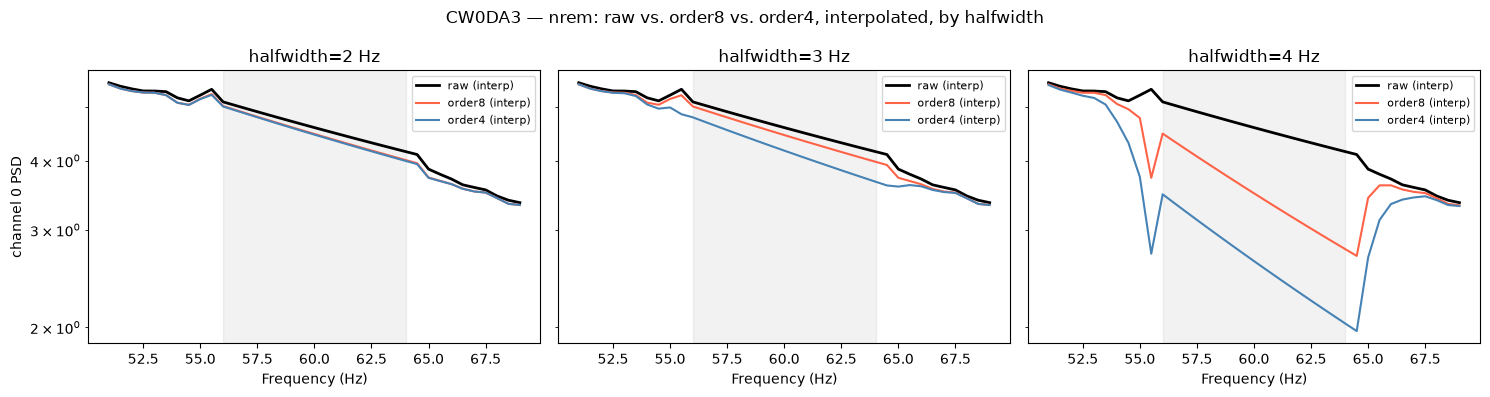

In [19]:
zoom_lo, zoom_hi = INTERP_RANGE[0] - 5, INTERP_RANGE[1] + 5
zoom_mask = (freqs >= zoom_lo) & (freqs <= zoom_hi)

r_raw_i = raw_by_key_interp[(animal, behavior)]

fig, axes = plt.subplots(1, len(NOTCH_HALFWIDTHS), figsize=(5 * len(NOTCH_HALFWIDTHS), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, hw in zip(axes, NOTCH_HALFWIDTHS):
    r_o8_i = order8_by_key_by_hw_interp[hw][(animal, behavior)]
    r_o4_i = order4_by_key_by_hw_interp[hw][(animal, behavior)]
    ax.semilogy(freqs[zoom_mask], r_raw_i["psd"][0][zoom_mask], label="raw (interp)", color="black", lw=2)
    ax.semilogy(freqs[zoom_mask], r_o8_i["psd"][0][zoom_mask], label="order8 (interp)", color="tomato")
    ax.semilogy(freqs[zoom_mask], r_o4_i["psd"][0][zoom_mask], label="order4 (interp)", color="steelblue")
    ax.axvspan(*INTERP_RANGE, color="gray", alpha=0.1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_title(f"halfwidth={hw} Hz")
    ax.legend(fontsize=8)
axes[0].set_ylabel(f"channel {channels[0]} PSD")
fig.suptitle(f"{animal} — {behavior}: raw vs. order8 vs. order4, interpolated, by halfwidth")
fig.tight_layout()

## Single-animal overlay swept across interpolation configs

Same output as "Single-animal overlay: raw vs. order8 vs. order4
(interpolated)" above -- one figure per interpolation config, each with one
subplot per halfwidth -- but everything you'd want to change (animal,
behavior, channel, and the list of interpolation `range`/`buffer` combos to
try) is defined in the single cell below, so there's no need to scroll
elsewhere in the notebook to adjust it.

Each combo's curves are interpolated fresh, just for the selected
animal/behavior/channel, so any `range`/`buffer` you list here works --
not just the ones already computed earlier in the notebook.

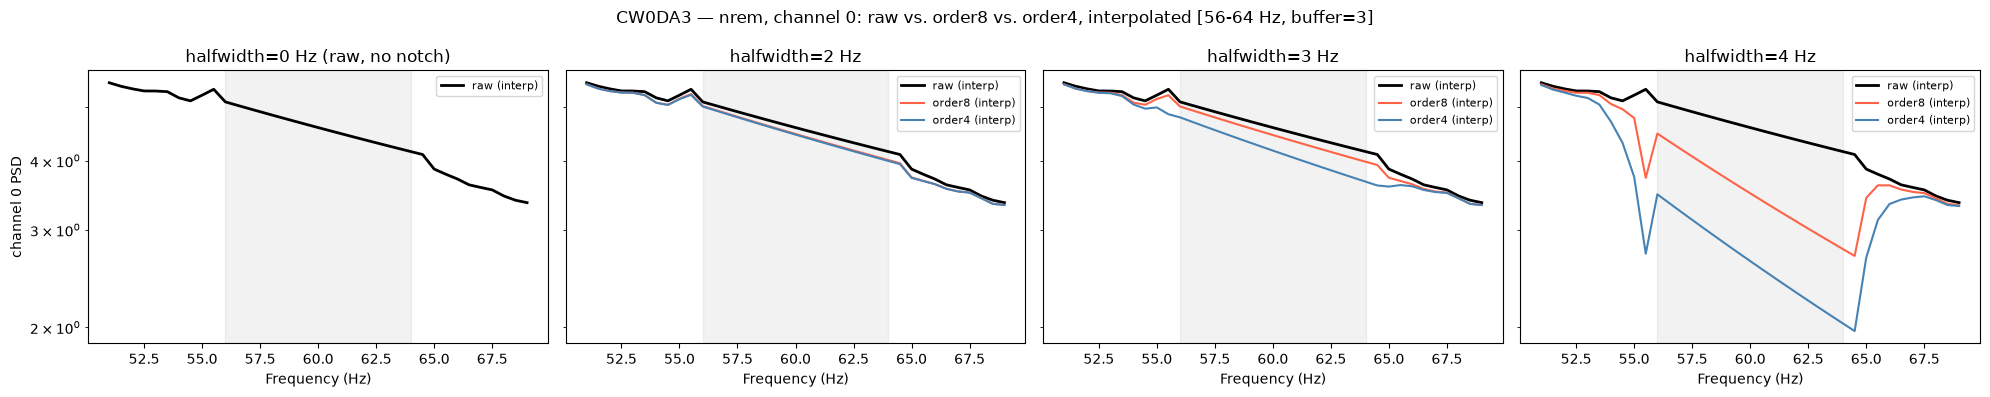

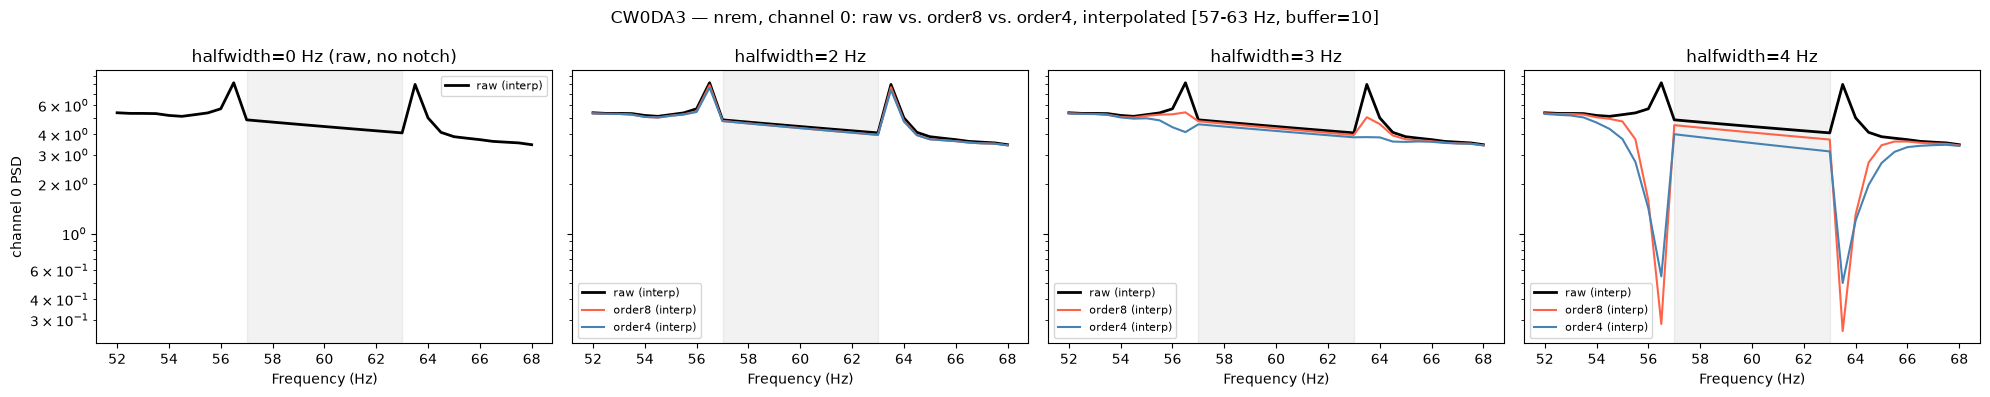

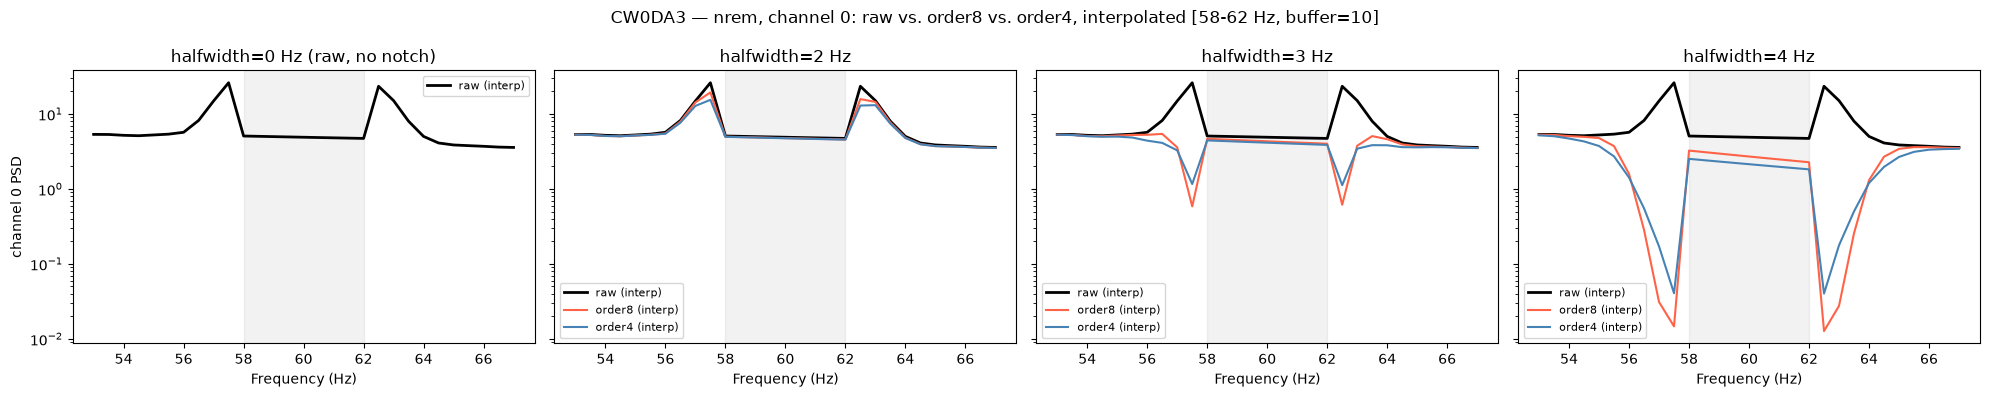

In [20]:
from specparam.utils.spectral import interpolate_spectrum

# --- Edit everything here ---
ANIMAL = "CW0DA3"
BEHAVIOR = "nrem"  # "wake" / "nrem" / "rem"
CHANNEL = 0  # index into r_raw["channels"] / r_raw["psd"]

INTERP_CONFIGS = [
    {"range": [56, 64], "buffer": 3},
    {"range": [57, 63], "buffer": 10},
    {"range": [58, 62], "buffer": 10},
]
# ---

available_animals = sorted({a for a, b in common_keys})
if (ANIMAL, BEHAVIOR) not in common_keys:
    raise ValueError(
        f"{(ANIMAL, BEHAVIOR)!r} not in common_keys.\n"
        f"Available animals: {available_animals}\n"
        f"Available behaviors: {sorted({b for a, b in common_keys})}"
    )
_animal, _behavior = ANIMAL, BEHAVIOR
_r_raw = raw_by_key[(_animal, _behavior)]
_freqs = np.asarray(_r_raw["freqs"])
_n_channels = len(_r_raw["channels"])
if not (0 <= CHANNEL < _n_channels):
    raise ValueError(f"CHANNEL={CHANNEL} out of range; this dataset has channels 0..{_n_channels - 1}")

panel_halfwidths = [0] + NOTCH_HALFWIDTHS  # 0 = raw, no notch at all -- a control panel

for cfg in INTERP_CONFIGS:
    interp_range, buffer = cfg["range"], cfg["buffer"]

    def _interp(psd_1d, interp_range=interp_range, buffer=buffer):
        return interpolate_spectrum(_freqs, psd_1d, interp_range, buffer=buffer)[1]

    raw_curve = _interp(_r_raw["psd"][CHANNEL])
    zoom_lo, zoom_hi = interp_range[0] - 5, interp_range[1] + 5
    zoom_mask = (_freqs >= zoom_lo) & (_freqs <= zoom_hi)

    fig, axes = plt.subplots(1, len(panel_halfwidths), figsize=(5 * len(panel_halfwidths), 4), sharey=True)
    axes = np.atleast_1d(axes)

    ax0 = axes[0]
    ax0.semilogy(_freqs[zoom_mask], raw_curve[zoom_mask], label="raw (interp)", color="black", lw=2)
    ax0.axvspan(*interp_range, color="gray", alpha=0.1)
    ax0.set_xlabel("Frequency (Hz)")
    ax0.set_title("halfwidth=0 Hz (raw, no notch)")
    ax0.legend(fontsize=8)

    for ax, hw in zip(axes[1:], NOTCH_HALFWIDTHS):
        o8_curve = _interp(order8_by_key_by_hw[hw][(_animal, _behavior)]["psd"][CHANNEL])
        o4_curve = _interp(order4_by_key_by_hw[hw][(_animal, _behavior)]["psd"][CHANNEL])
        ax.semilogy(_freqs[zoom_mask], raw_curve[zoom_mask], label="raw (interp)", color="black", lw=2)
        ax.semilogy(_freqs[zoom_mask], o8_curve[zoom_mask], label="order8 (interp)", color="tomato")
        ax.semilogy(_freqs[zoom_mask], o4_curve[zoom_mask], label="order4 (interp)", color="steelblue")
        ax.axvspan(*interp_range, color="gray", alpha=0.1)
        ax.set_xlabel("Frequency (Hz)")
        ax.set_title(f"halfwidth={hw} Hz")
        ax.legend(fontsize=8)

    axes[0].set_ylabel(f"channel {CHANNEL} PSD")
    fig.suptitle(
        f"{_animal} — {_behavior}, channel {CHANNEL}: raw vs. order8 vs. order4, interpolated "
        f"[{interp_range[0]}-{interp_range[1]} Hz, buffer={buffer}]"
    )
    fig.tight_layout()
    plt.show()